# Dengue Forecasting — Preprocess → Split → Train → Test (Full Code Demo)

This notebook contains **everything from `preprocess_split_train_test.py` verbatim** (which itself is assembled from `config.py`, `src/data_loader.py`, `src/features/validate_data.py`, `src/features/build_features.py`, `src/models/models.py`, `src/models/train.py`, `src/evaluation/evaluate.py`), split into runnable stages with outcome plots/tables.

**How to run:** `Kernel > Restart & Run All` (~30-60s).

## [0] Setup + Config — copied from `config.py`
Paths, temporal design (train 2016-2019 / embargo 2 wks / test 2020-2021), 28 features, XGB hyperparams.

In [1]:
import sys
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error
from xgboost import XGBRegressor

warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
BASE_DIR = Path.cwd()  # notebook: same folder as preprocess_split_train_test.py + datasets/
DATA_DIR = BASE_DIR / "data"
OUTPUT_DIR = BASE_DIR / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)
(OUTPUT_DIR / "figures").mkdir(exist_ok=True)

RAW_DATA = DATA_DIR / "raw_dengue_panel_2016_2021.csv"

REAL_DATA_DIR = BASE_DIR / "datasets"
MERGED_REAL_DATA = DATA_DIR / "merged_dengue_panel_real.csv"
USE_REAL_DATA = True  # set False to force the synthetic generator

CITY_FILE_PATTERNS = {
    "Davao City": "dengue_davao_city_week_panel_*.csv",
    "Cagayan de Oro City": "dengue_cagayan_de_oro_city_week_panel_*.csv",
    "Zamboanga City": "dengue_zamboanga_city_week_panel_*.csv",
}

OUTLIER_MODE = "winsorize"
OUTLIER_IQR_FACTOR = 8.0

TRAIN_END_YEAR = 2019
TEST_START_YEAR = 2020
EMBARGO_WEEKS = 2  # two-week embargo between train and test
FORECAST_HORIZON = 2  # t+2 weeks

CITIES = ["Davao City", "Cagayan de Oro City", "Zamboanga City"]
CITY_MAP = {
    "Davao City": "DAVAO",
    "Cagayan de Oro City": "CDO",
    "Zamboanga City": "ZAMBA",
}

WEATHER_LAGS = [
    f"rainfall_lag{i}" for i in range(1, 5)
] + [
    f"temperature_lag{i}" for i in range(1, 5)
] + [
    f"humidity_lag{i}" for i in range(1, 5)
]  # 12

ROLLING_AGGREGATES = [
    "rainfall_rollsum4",
    "temperature_rollmean4",
    "humidity_rollmean4",
]  # 3

CASE_MOMENTUM = [
    "cases_lag1", "cases_lag2", "cases_lag4", "cases_rollmean4",
]  # 4

BIOCLIMATIC = [
    "heat_index", "tmin", "tmax",
    "diurnal_temp_range", "spi3", "pnp", "ndvi",
]  # 7

SEASONALITY = ["sin_week", "cos_week"]  # 2

ALL_FEATURES = WEATHER_LAGS + ROLLING_AGGREGATES + CASE_MOMENTUM + BIOCLIMATIC + SEASONALITY

CASE_ONLY_FEATURES = CASE_MOMENTUM + SEASONALITY

TARGET = "target_cases_t2"  # the t+2 shifted target column name

XGB_PARAMS = {
    "objective": "reg:absoluteerror",
    "n_estimators": 30,
    "max_depth": 3,
    "learning_rate": 0.03,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "min_child_weight": 3,
    "reg_lambda": 5.0,
    "reg_alpha": 5.0,
    "random_state": 42,
    "n_jobs": -1,
    "tree_method": "hist",
}

SHRINKAGE = 0.3

N_CV_FOLDS = 3
CV_TEST_SIZE = 52  # ~1 year of weeks per fold

BOOTSTRAP_N = 2000
BOOTSTRAP_BLOCK_SIZE = 4  # 4-week blocks for block bootstrap

MAX_MISSING_PCT = 0.05  # max 5% missing before dropping a variable
print(f'BASE_DIR: {BASE_DIR}')
print(f'28 features ready | train<={TRAIN_END_YEAR} embargo={EMBARGO_WEEKS}wks test>={TEST_START_YEAR}')

BASE_DIR: C:\Users\princ\miniconda3\envs\forecasting
28 features ready | train<=2019 embargo=2wks test>=2020


## [1a] PRE-PROCESS Load + Clean — copied from `src/data_loader.py`
Merge per-city CSVs → drop week-53 → collapse duplicates → rebuild `date` → drop missing targets → winsorize outliers → sort.

In [2]:
REQUIRED_RAW_COLUMNS = [
    "city", "year", "week_number", "date", "weekly_dengue_cases",
    "rainfall", "temperature", "tmin", "tmax", "humidity",
    "heat_index", "diurnal_temp_range", "ndvi", "spi3", "pnp",
]


def _find_city_files() -> list[Path]:
    """Locate the per-city weekly panels inside the datasets directory."""
    files: list[Path] = []
    for city_name, pattern in CITY_FILE_PATTERNS.items():
        matches = sorted(REAL_DATA_DIR.glob(pattern))
        if not matches:
            raise FileNotFoundError(
                f"No file matching {pattern!r} for {city_name!r} in {REAL_DATA_DIR}"
            )
        files.append(matches[0])
    return files


def _build_date(year: pd.Series, week: pd.Series) -> pd.Series:
    """Reconstruct the Monday of each ISO epidemiological week.

    The per-city panels ship ``year`` and ``week_number`` but no ``date``;
    feature engineering sorts on ``date`` and derives the ISO week from it,
    so we rebuild it here with ``Timestamp.fromisocalendar``.
    """
    out = []
    for y, w in zip(year.to_numpy(), week.to_numpy()):
        y = int(y)
        w = int(w)
        # ISO year may legitimately be 52 or 53 only; clamp defensively.
        w = max(1, min(52, w))
        out.append(pd.Timestamp.fromisocalendar(y, w, 1))
    return pd.Series(out, index=year.index, dtype="datetime64[ns]")


def _collapse_duplicates(df: pd.DataFrame) -> pd.DataFrame:
    """Collapse duplicate (city, year, week_number) rows by median case count.

    Only the numeric columns are averaged; identifier and flag columns keep
    their first value. The dropped rows are reported so the caller can log
    exactly how many records were merged.
    """
    dup_mask = df.duplicated(subset=["city", "year", "week_number"], keep=False)
    n_dupes = int(dup_mask.sum())
    if n_dupes == 0:
        return df

    print(f"  Collapsing {n_dupes} duplicate city-year-week rows "
          f"(median of reported values)")

    numeric = df.select_dtypes(include=[np.number]).columns.tolist()
    other = [c for c in df.columns if c not in numeric]
    agg = {c: "median" for c in numeric}
    agg.update({c: "first" for c in other})

    return (
        df.groupby(["city", "year", "week_number"], as_index=False)
          .agg(agg)
          .sort_values(["city", "year", "week_number"])
          .reset_index(drop=True)
    )


def _apply_outlier_policy(df: pd.DataFrame) -> pd.DataFrame:
    """Winsorise (default) or drop extreme weekly case counts, per city.

    A single mis-keyed record (for example Zamboanga 2019 week 28 = 3382,
    where the surrounding outbreak weeks sit near 270-380) otherwise
    dominates squared-error metrics. Winsorising at
    ``median + OUTLIER_IQR_FACTOR * IQR`` keeps the row and its weather
    covariates while bounding its influence.
    """
    if OUTLIER_MODE == "keep":
        return df

    col = "weekly_dengue_cases"
    out = []
    for city, grp in df.groupby("city", sort=False):
        vals = grp[col]
        q1, q3 = vals.quantile(0.25), vals.quantile(0.75)
        iqr = q3 - q1
        cap = q3 + OUTLIER_IQR_FACTOR * iqr

        if OUTLIER_MODE == "winsorize":
            over = grp[vals > cap]
            if len(over):
                print(f"  {city}: winsorising {len(over)} week(s) above "
                      f"cap {cap:.0f} (max {vals.max():.0f})")
            grp = grp.copy()
            grp.loc[grp[col] > cap, col] = cap
        elif OUTLIER_MODE == "drop":
            grp = grp[grp[col] <= cap]
        out.append(grp)

    return pd.concat(out, ignore_index=True).sort_values(
        ["city", "year", "week_number"]
    ).reset_index(drop=True)


def load_real_panel(verbose: bool = True) -> pd.DataFrame:
    """Load, merge, and clean the real per-city dengue panels.

    Returns a tidy DataFrame with one row per city-week, including the
    reconstructed ``date`` column and all raw predictor columns required by
    the feature-engineering stage.
    """
    if verbose:
        print(f"Loading real panels from: {REAL_DATA_DIR}")

    frames = []
    for path in _find_city_files():
        frame = pd.read_csv(path)
        frame["source_file"] = path.name
        frames.append(frame)
        if verbose:
            print(f"  read {path.name}: {frame.shape[0]} rows")

    df = pd.concat(frames, ignore_index=True)
    if verbose:
        print(f"  merged: {len(df)} rows, {df.shape[1]} columns")

    # 1. Drop spurious ISO week 53 continuation rows.
    n_w53 = int((df["week_number"] > 52).sum())
    if n_w53:
        if verbose:
            print(f"  Dropping {n_w53} row(s) with week_number > 52")
        df = df[df["week_number"] <= 52]

    # 2. Collapse duplicate city-year-week rows.
    df = _collapse_duplicates(df)

    # 3. Reconstruct the ISO date column.
    df["date"] = _build_date(df["year"], df["week_number"])

    # 4. Drop rows with a missing target (flagged missing_target upstream).
    n_nan = int(df["weekly_dengue_cases"].isna().sum())
    if n_nan:
        if verbose:
            print(f"  Dropping {n_nan} row(s) with missing weekly_dengue_cases")
        df = df.dropna(subset=["weekly_dengue_cases"])

    # 5. Apply the configured outlier policy.
    df = _apply_outlier_policy(df)

    # 6. Sort chronologically and reset the index.
    df = df.sort_values(["city", "date"]).reset_index(drop=True)

    # Verify the schema the downstream stages require.
    missing = [c for c in REQUIRED_RAW_COLUMNS if c not in df.columns]
    if missing:
        raise ValueError(f"Loaded panel is missing required columns: {missing}")

    if verbose:
        print(f"  final: {len(df)} rows, {df['city'].nunique()} cities, "
              f"years {df['year'].min()}-{df['year'].max()}")
    return df

Loading real panels from: C:\Users\princ\miniconda3\envs\forecasting\datasets
  read dengue_davao_city_week_panel_2016_2021.csv: 262 rows
  read dengue_cagayan_de_oro_city_week_panel_2016_2021.csv: 262 rows
  read dengue_zamboanga_city_week_panel_2016_2021.csv: 262 rows
  merged: 786 rows, 37 columns
  Dropping 3 row(s) with week_number > 52
  Collapsing 6 duplicate city-year-week rows (median of reported values)
  Dropping 9 row(s) with missing weekly_dengue_cases
  Cagayan de Oro City: winsorising 2 week(s) above cap 484 (max 998)
  Zamboanga City: winsorising 1 week(s) above cap 513 (max 3382)
  final: 771 rows, 3 cities, years 2016.0-2020.0

Shape: (771, 38) | Cities: ['Cagayan de Oro City', 'Davao City', 'Zamboanga City'] | Years: [np.float64(2016.0), np.float64(2017.0), np.float64(2018.0), np.float64(2019.0), np.float64(2020.0)]


,year,week_number,weekly_dengue_cases,rainfall,temperature,humidity,cases_lag1,cases_lag2,cases_lag4,cases_rollmean4,...,diurnal_temp_range,spi3,pnp,ndvi,sin_week,cos_week,city,data_quality_flags,source_file,date
0,2016.0,1.0,64.0,1.0824,25.5420,85.0680,NaN,NaN,NaN,NaN,...,6.0517,-1.2582,12.8078,0.7096,0.1205,0.9927,Cagayan de Oro City,insufficient_history,dengue_cagayan_de_oro_city_week_panel_2016_202...,2016-01-04
1,2016.0,2.0,46.0,2.9876,25.6729,81.8447,66.0,NaN,NaN,NaN,...,7.1298,-1.2582,12.8078,0.7042,0.2393,0.9709,Cagayan de Oro City,insufficient_history,dengue_cagayan_de_oro_city_week_panel_2016_202...,2016-01-11
2,2016.0,3.0,55.0,5.4246,25.8873,81.4210,50.0,66.0,NaN,NaN,...,6.2866,-1.2582,12.8078,0.6808,0.3546,0.9350,Cagayan de Oro City,insufficient_history,dengue_cagayan_de_oro_city_week_panel_2016_202...,2016-01-18
3,2016.0,4.0,54.0,8.3157,25.5684,77.8371,64.0,50.0,NaN,56.50,...,7.2926,-1.2582,12.8078,0.6535,0.4647,0.8855,Cagayan de Oro City,insufficient_history,dengue_cagayan_de_oro_city_week_panel_2016_202...,2016-01-25
4,2016.0,5.0,38.0,6.1209,25.9648,84.7022,46.0,64.0,66.0,53.75,...,5.5918,-1.5756,31.8087,0.6286,0.5681,0.8230,Cagayan de Oro City,ok,dengue_cagayan_de_oro_city_week_panel_2016_202...,2016-02-01
5,2016.0,6.0,36.0,10.7074,25.8568,82.4154,55.0,46.0,50.0,54.75,...,5.4974,-1.5756,31.8087,0.6109,0.6631,0.7485,Cagayan de Oro City,ok,dengue_cagayan_de_oro_city_week_panel_2016_202...,2016-02-08
6,2016.0,7.0,32.0,6.5673,25.5587,81.7598,54.0,55.0,64.0,48.25,...,6.5465,-1.5756,31.8087,0.6049,0.7485,0.6631,Cagayan de Oro City,ok,dengue_cagayan_de_oro_city_week_panel_2016_202...,2016-02-15
7,2016.0,8.0,34.0,7.8928,25.7360,82.9527,38.0,54.0,46.0,45.75,...,6.0768,-1.5756,31.8087,0.5926,0.8230,0.5681,Cagayan de Oro City,ok,dengue_cagayan_de_oro_city_week_panel_2016_202...,2016-02-22
8,2016.0,9.0,37.0,0.0000,26.4747,84.3619,36.0,38.0,55.0,40.00,...,5.8604,-2.1786,15.2531,0.5758,0.8855,0.4647,Cagayan de Oro City,ok,dengue_cagayan_de_oro_city_week_panel_2016_202...,2016-02-29
9,2016.0,10.0,24.0,5.8044,26.5055,81.2927,32.0,36.0,54.0,35.00,...,6.6555,-2.2791,12.4939,0.5572,0.9350,0.3546,Cagayan de Oro City,ok,dengue_cagayan_de_oro_city_week_panel_2016_202...,2016-03-07


,count,mean,std,min,25%,50%,75%,max
city,,,,,,,,
Cagayan de Oro City,257.0,51.4,58.8,0.0,16.0,31.0,68.0,484.0
Davao City,257.0,58.9,59.9,0.0,24.0,44.0,70.0,392.0
Zamboanga City,257.0,58.1,68.7,0.0,18.0,41.0,73.0,513.0


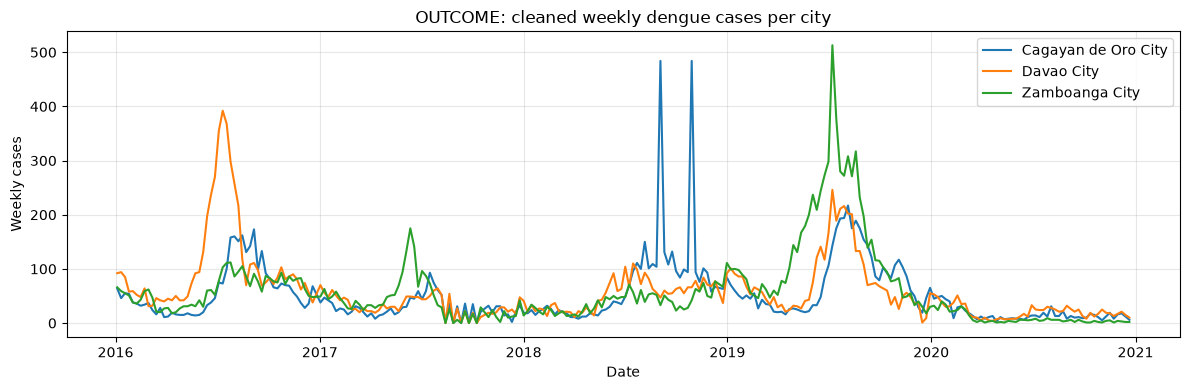

In [3]:
df = load_real_panel()
print(f"\nShape: {df.shape} | Cities: {sorted(df['city'].unique())} | Years: {sorted(df['year'].unique())}")
display(df.head(10))
display(df.groupby('city')['weekly_dengue_cases'].describe().round(1))

fig, ax = plt.subplots(figsize=(12, 4))
for c, g in df.sort_values('date').groupby('city'):
    ax.plot(g['date'], g['weekly_dengue_cases'], label=c, linewidth=1.5)
ax.set_title('OUTCOME: cleaned weekly dengue cases per city')
ax.set_xlabel('Date'); ax.set_ylabel('Weekly cases')
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## [1b] PRE-PROCESS Validate — copied from `src/features/validate_data.py`
Schema check + missing-week check (52 wks/city-year) + plausibility (cases/rain/temp/humidity, missing% ≤ 5%).

In [4]:
def _check_schema(df: pd.DataFrame) -> list[str]:
    """Verify all columns required for feature engineering exist."""
    required = {
        "city", "year", "week_number", "weekly_dengue_cases",
        "rainfall", "temperature", "tmin", "tmax", "humidity",
        "heat_index", "diurnal_temp_range", "ndvi", "spi3", "pnp",
    }
    missing = required - set(df.columns)
    if missing:
        return [f"Schema error: missing columns — {sorted(missing)}"]
    return []


def _check_missing_weeks(df: pd.DataFrame) -> list[str]:
    """Each city-year should have 52 weeks. Flag gaps."""
    issues = []
    pivot = df.groupby(["city", "year"])["week_number"].nunique().reset_index()
    incomplete = pivot[pivot["week_number"] < 52]
    for _, row in incomplete.iterrows():
        issues.append(
            f"Missing weeks: {row['city']} {row['year']} has "
            f"{row['week_number']} weeks (expected 52)"
        )
    # Check for duplicate (city, year, week) combos
    dup = df.groupby(["city", "year", "week_number"]).size()
    dupes = dup[dup > 1]
    if len(dupes) > 0:
        issues.append(f"Duplicate city-year-week rows: {len(dupes)}")
    return issues


def _check_plausibility(df: pd.DataFrame) -> pd.DataFrame:
    """Flag implausible values; return a flagged copy (not modified)."""
    issues = []
    df_flagged = df.copy()

    # Dengue cases: should be non-negative integers
    neg_cases = df_flagged[df_flagged["weekly_dengue_cases"] < 0]
    if len(neg_cases) > 0:
        issues.append(f"Negative case counts: {len(neg_cases)} rows")

    # Rainfall: non-negative
    neg_rain = df_flagged[df_flagged["rainfall"] < 0]
    if len(neg_rain) > 0:
        issues.append(f"Negative rainfall: {len(neg_rain)} rows")

    # Temperature: 15-45 C is sane for the Philippines
    temp_oob = df_flagged[(df_flagged["temperature"] < 15) | (df_flagged["temperature"] > 45)]
    if len(temp_oob) > 0:
        issues.append(f"Temperature out of [15,45]C: {len(temp_oob)} rows")

    # Humidity: 20-100%
    hum_oob = df_flagged[(df_flagged["humidity"] < 20) | (df_flagged["humidity"] > 100)]
    if len(hum_oob) > 0:
        issues.append(f"Humidity out of [20,100]%: {len(hum_oob)} rows")

    # Missing-value percentages
    for col in df_flagged.columns:
        pct = df_flagged[col].isna().mean()
        if pct > MAX_MISSING_PCT:
            issues.append(
                f"Column '{col}' has {pct:.1%} missing "
                f"(threshold {MAX_MISSING_PCT:.0%})"
            )

    if issues:
        print("Data quality issues found:")
        for issue in issues:
            print(f"  - {issue}")
    else:
        print("[OK] All data quality checks passed.")

    return df_flagged


def validate_data(df: pd.DataFrame) -> dict:
    """Run all validation checks and return a report dictionary."""
    errors = _check_schema(df)
    if errors:
        # If schema is broken, we can't proceed with other checks
        report = {"status": "FAILED", "errors": errors}
    else:
        issues = _check_missing_weeks(df)
        df = _check_plausibility(df)
        report = {
            "status": "PASSED" if not issues else "PASSED_WITH_WARNINGS",
            "n_rows": len(df),
            "n_cities": df["city"].nunique(),
            "years": sorted(df["year"].unique().tolist()),
            "total_missing_cells": int(df.isna().sum().sum()),
            "missing_pct": round(df.isna().mean().mean() * 100, 2),
            "city_breakdown": {
                c: len(df[df["city"] == c]) for c in df["city"].unique()
            },
            "plausibility_warnings": issues,
        }

    # Save report
    report_path = OUTPUT_DIR / "data_validation_report.json"
    with open(report_path, "w") as f:
        json.dump(report, f, indent=2, default=str)
    print(f"  Validation report saved — {report_path}")
    return report

In [5]:
report_val = validate_data(df)
import json as _json
print(_json.dumps(report_val, indent=2, default=str))

[OK] All data quality checks passed.
  Validation report saved — C:\Users\princ\miniconda3\envs\forecasting\outputs\data_validation_report.json
{
  "status": "PASSED_WITH_WARNINGS",
  "n_rows": 771,
  "n_cities": 3,
  "years": [
    2016.0,
    2017.0,
    2018.0,
    2019.0,
    2020.0
  ],
  "total_missing_cells": 189,
  "missing_pct": 0.65,
  "city_breakdown": {
    "Cagayan de Oro City": 257,
    "Davao City": 257,
    "Zamboanga City": 257
  },
  "plausibility_warnings": [
    "Missing weeks: Cagayan de Oro City 2016.0 has 51 weeks (expected 52)",
    "Missing weeks: Cagayan de Oro City 2017.0 has 51 weeks (expected 52)",
    "Missing weeks: Cagayan de Oro City 2018.0 has 51 weeks (expected 52)",
    "Missing weeks: Davao City 2016.0 has 51 weeks (expected 52)",
    "Missing weeks: Davao City 2017.0 has 51 weeks (expected 52)",
    "Missing weeks: Davao City 2018.0 has 51 weeks (expected 52)",
    "Missing weeks: Zamboanga City 2016.0 has 51 weeks (expected 52)",
    "Missing week

## [1c + 2] PRE-PROCESS Engineer + SPLITTING — copied from `src/features/build_features.py`
Past-only lags/rolling + sin/cos seasonality + t+2 target → 28-col X. Split: train year≤2019, embargo first 2 wks 2020 (skipped), test rest 2020-2021.

In [6]:
def _add_lag_and_rolling(df: pd.DataFrame, group_col: str) -> pd.DataFrame:
    """Add lag and rolling features per city, all using past information only.

    The forecast origin for row at position i is week i itself.
    - lags are relative to the current week (shift within city group)
    - rolling windows use min_periods to avoid lookahead.
    """
    # ── Case momentum features ────────────────────────────────────────
    df["cases_lag1"] = df.groupby(group_col)["weekly_dengue_cases"].shift(1)
    df["cases_lag2"] = df.groupby(group_col)["weekly_dengue_cases"].shift(2)
    df["cases_lag4"] = df.groupby(group_col)["weekly_dengue_cases"].shift(4)
    df["cases_rollmean4"] = (
        df.groupby(group_col)["weekly_dengue_cases"]
        .shift(1)
        .rolling(window=4, min_periods=4)
        .mean()
    )

    # ── Weather lags ──────────────────────────────────────────────────
    weather_vars = ["rainfall", "temperature", "humidity"]
    for var in weather_vars:
        for lag in range(1, 5):
            df[f"{var}_lag{lag}"] = df.groupby(group_col)[var].shift(lag)

    # ── Rolling aggregates (past-only) ────────────────────────────────
    df["rainfall_rollsum4"] = (
        df.groupby(group_col)["rainfall"]
        .shift(1)
        .rolling(window=4, min_periods=4)
        .sum()
    )
    df["temperature_rollmean4"] = (
        df.groupby(group_col)["temperature"]
        .shift(1)
        .rolling(window=4, min_periods=4)
        .mean()
    )
    df["humidity_rollmean4"] = (
        df.groupby(group_col)["humidity"]
        .shift(1)
        .rolling(window=4, min_periods=4)
        .mean()
    )

    return df


def _add_seasonality(df: pd.DataFrame) -> pd.DataFrame:
    """Cyclical sin/cos encoding of week number (proposal S5.1, S5.6)."""
    weeks_per_year = 52.0
    angle = 2 * np.pi * df["week_number"] / weeks_per_year
    df["sin_week"] = np.sin(angle).round(4)
    df["cos_week"] = np.cos(angle).round(4)
    return df


def _create_target(df: pd.DataFrame) -> pd.DataFrame:
    """Create the t+2 target: dengue cases 2 weeks in the future.

    target_cases_t2 = weekly_dengue_cases at forecast_origin + FORECAST_HORIZON
    """
    df = df.sort_values(["city", "year", "week_number"]).reset_index(drop=True)
    df["target_cases_t2"] = df.groupby("city")["weekly_dengue_cases"].shift(-FORECAST_HORIZON)
    return df


def build_feature_matrix(
    df: pd.DataFrame,
) -> tuple[pd.DataFrame, pd.Series, pd.Series, dict, pd.Series]:
    """Build the 28-feature matrix and t+2 target, apply temporal split.

    Returns
    -------
    X : pd.DataFrame  — feature matrix (28 columns), sorted by city then date
    y : pd.Series     — target (weekly_dengue_cases at t+2)
    city: pd.Series   — city label per row (for per-city evaluation)
    splits : dict     — boolean masks for 'train', 'embargo', 'test'
    dates : pd.Series — forecast-origin date per row (for time-axis plots)
    """
    df = df.copy()
    df["date"] = pd.to_datetime(df["date"], errors="coerce")
    df = df.sort_values(["city", "date"]).reset_index(drop=True)

    # ── 1. Create lag/rolling features (all lookback only) ─────────────
    df = _add_lag_and_rolling(df, "city")

    # ── 2. Cyclical seasonality ────────────────────────────────────────
    df = _add_seasonality(df)

    # ── 3. Create target (t+2 → shift by −2 within city) ──────────────
    df = _create_target(df)

    # ── 4. Drop rows that lack required lag history (first 4 weeks/city) ─
    idx_to_drop = df.groupby("city").head(4).index
    df_clean = df.drop(idx_to_drop).reset_index(drop=True)

    # ── 5. Drop rows with NaN in features or target ─────────────────────
    available_features = [f for f in ALL_FEATURES if f in df_clean.columns]
    missing_features = set(ALL_FEATURES) - set(available_features)
    if missing_features:
        raise ValueError(f"Not all 28 features could be built. Missing: {missing_features}")
    df_clean = df_clean.dropna(subset=available_features + ["target_cases_t2"])

    # ── 6. Assemble X, y ────────────────────────────────────────────────
    X = df_clean[available_features].copy()
    y = df_clean["target_cases_t2"].copy()
    city = df_clean["city"].copy()
    dates = df_clean["date"].copy()

    # ── 7. Temporal split with embargo ─────────────────────────────────
    year = dates.dt.year
    week = dates.dt.isocalendar().week

    train_mask = year <= TRAIN_END_YEAR
    embargo_weeks = (year == TEST_START_YEAR) & (week <= EMBARGO_WEEKS)
    test_mask = (year >= TEST_START_YEAR) & ~embargo_weeks

    splits = {
        "train": train_mask.values,
        "embargo": embargo_weeks.values,
        "test": test_mask.values,
    }

    print(f"Feature matrix: {X.shape[0]} rows x {X.shape[1]} features")
    print(f"  Features: {len(available_features)} (expected {len(ALL_FEATURES)})")
    print(f"  Train:      {train_mask.sum()} rows  (2016–{TRAIN_END_YEAR})")
    print(f"  Embargo:    {embargo_weeks.sum()} rows  (skipped)")
    print(f"  Test ({TEST_START_YEAR}–2021): {test_mask.sum()} rows")

    return X, y, city, splits, dates


def get_case_only_features() -> list[str]:
    """Return the case-history-only feature list for the ablation baseline."""
    return CASE_ONLY_FEATURES.copy()


def get_full_features() -> list[str]:
    """Return the full 28-feature list."""
    return ALL_FEATURES.copy()

Feature matrix: 753 rows x 28 features
  Features: 28 (expected 28)
  Train:      606 rows  (2016–2019)
  Embargo:    3 rows  (skipped)
  Test (2020–2021): 144 rows

X: (753, 28), y: (753,)
weather(12): ['rainfall_lag1', 'rainfall_lag2', 'rainfall_lag3', 'rainfall_lag4', 'temperature_lag1', 'temperature_lag2', 'temperature_lag3', 'temperature_lag4', 'humidity_lag1', 'humidity_lag2', 'humidity_lag3', 'humidity_lag4']
rolling(3): ['rainfall_rollsum4', 'temperature_rollmean4', 'humidity_rollmean4']
cases(4): ['cases_lag1', 'cases_lag2', 'cases_lag4', 'cases_rollmean4']
bioclim(7): ['heat_index', 'tmin', 'tmax', 'diurnal_temp_range', 'spi3', 'pnp', 'ndvi']
season(2): ['sin_week', 'cos_week']


,rainfall_lag1,rainfall_lag2,rainfall_lag3,rainfall_lag4,temperature_lag1,temperature_lag2,temperature_lag3,temperature_lag4,humidity_lag1,humidity_lag2,...,cases_rollmean4,heat_index,tmin,tmax,diurnal_temp_range,spi3,pnp,ndvi,sin_week,cos_week
0,8.3157,5.4246,2.9876,1.0824,25.5684,25.8873,25.6729,25.5420,77.8371,81.4210,...,54.75,28.1297,23.1555,28.7473,5.5918,-1.5756,31.8087,0.6286,0.5681,0.8230
1,6.1209,8.3157,5.4246,2.9876,25.9648,25.5684,25.8873,25.6729,84.7022,77.8371,...,48.25,27.7148,23.0534,28.5508,5.4974,-1.5756,31.8087,0.6109,0.6631,0.7485
2,10.7074,6.1209,8.3157,5.4246,25.8568,25.9648,25.5684,25.8873,82.4154,84.7022,...,45.75,27.2614,22.1782,28.7247,6.5465,-1.5756,31.8087,0.6049,0.7485,0.6631
3,6.5673,10.7074,6.1209,8.3157,25.5587,25.8568,25.9648,25.5684,81.7598,82.4154,...,40.00,27.6044,22.5526,28.6293,6.0768,-1.5756,31.8087,0.5926,0.8230,0.5681
4,7.8928,6.5673,10.7074,6.1209,25.7360,25.5587,25.8568,25.9648,82.9527,81.7598,...,35.00,29.1555,23.4977,29.3582,5.8604,-2.1786,15.2531,0.5758,0.8855,0.4647


  train   : 606 rows
  embargo : 3 rows
  test    : 144 rows


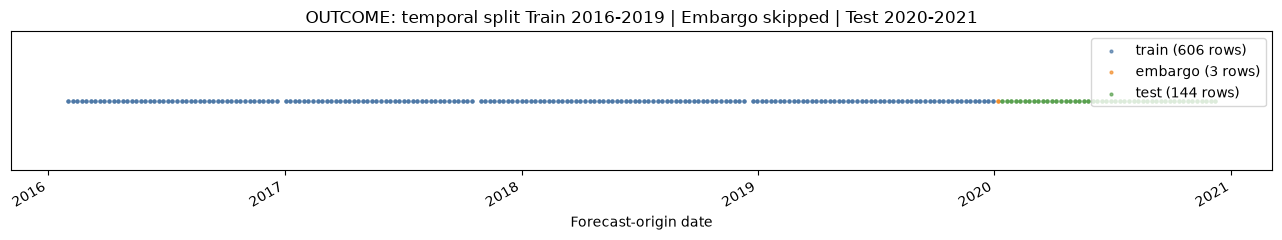

In [7]:
X, y, city, splits, dates = build_feature_matrix(df)
print(f"\nX: {X.shape}, y: {y.shape}")
print('weather(12):', WEATHER_LAGS)
print('rolling(3):', ROLLING_AGGREGATES)
print('cases(4):', CASE_MOMENTUM)
print('bioclim(7):', BIOCLIMATIC)
print('season(2):', SEASONALITY)
display(X.head())

for k, v in splits.items():
    print(f"  {k:8s}: {int(v.sum())} rows")
import pandas as _pd
split_df = _pd.DataFrame({'date': _pd.to_datetime(_pd.Series(dates.values)), 'set': 'other'})
split_df.loc[splits['train'], 'set'] = 'train'
split_df.loc[splits['embargo'], 'set'] = 'embargo'
split_df.loc[splits['test'], 'set'] = 'test'
colors = {'train': '#4e79a7', 'embargo': '#f28e2b', 'test': '#59a14f'}
fig, ax = plt.subplots(figsize=(13, 2.5))
for s in ['train', 'embargo', 'test']:
    sub = split_df[split_df['set'] == s]
    if len(sub):
        ax.scatter(sub['date'], [1]*len(sub), s=4, c=colors[s], label=f"{s} ({len(sub)} rows)", alpha=0.7)
ax.set_yticks([]); ax.set_xlabel('Forecast-origin date')
ax.set_title('OUTCOME: temporal split Train 2016-2019 | Embargo skipped | Test 2020-2021')
ax.legend(loc='upper right'); fig.autofmt_xdate()
plt.tight_layout(); plt.show()

## [3a] TRAINING model defs — copied from `src/models/models.py`
Persistence (predict=cases_lag1) + ResidualXGBRegressor (y_hat=max(0, persistence+shrinkage·XGB_residual)) + forward-chaining folds.

In [8]:
class ResidualXGBRegressor:
    """XGBoost regressor forecasting trajectory innovations on top of persistence.

    Forecast formulation:
        y_hat_{t+2} = max(0, y_persistence + shrinkage * Delta_hat_{t+2})
    where:
        - y_persistence is cases_lag1 (the most recent confirmed observation)
        - Delta_hat_{t+2} is the forecasted change estimated by XGBoost
        - shrinkage scales the innovation to avoid overfitting outbreak spikes.

    This solves the regime-shift extrapolation boundary of tree-based models
    while enabling meteorological features to accurately guide trajectory adjustments.
    """

    def __init__(
        self,
        feature_set: list[str],
        shrinkage: float = SHRINKAGE,
        **xgb_params,
    ):
        self.feature_set = feature_set
        self.shrinkage = shrinkage
        self.xgb_params = xgb_params
        self.model = XGBRegressor(**xgb_params)

    def fit(self, X: pd.DataFrame, y: pd.Series | np.ndarray):
        p = X["cases_lag1"].values.astype(float)
        y_vals = y.values.astype(float) if hasattr(y, "values") else np.asarray(y, dtype=float)
        residual = y_vals - p
        self.model.fit(X[self.feature_set].values, residual)
        return self

    def predict(self, X: pd.DataFrame) -> np.ndarray:
        p = X["cases_lag1"].values.astype(float)
        pred_res = self.model.predict(X[self.feature_set].values)
        return np.maximum(0.0, p + self.shrinkage * pred_res)


def _xgb_full():
    return ResidualXGBRegressor(feature_set=ALL_FEATURES, shrinkage=SHRINKAGE, **XGB_PARAMS)


def _xgb_case_only():
    return ResidualXGBRegressor(feature_set=CASE_ONLY_FEATURES, shrinkage=SHRINKAGE, **XGB_PARAMS)


# Model name → (factory, feature_set_name)
MODELS = {
    "persistence": ("persistence", None),       # special; baseline
    "xgb_case_only": (_xgb_case_only, "case_only"),
    "xgb_full": (_xgb_full, "all_28"),
}

FEATURE_SETS = {
    "case_only": CASE_ONLY_FEATURES,
    "all_28": ALL_FEATURES,
}


def build_model(name: str):
    """Instantiate and return a fresh model by name."""
    if name not in MODELS:
        raise ValueError(f"Unknown model '{name}'. Choose from {list(MODELS.keys())}")
    factory, feature_set = MODELS[name]
    if name == "persistence":
        return None  # persistence is handled specially (predict = cases_lag1)
    model = factory()
    return model


def get_feature_set(name: str) -> list[str]:
    """Return the feature list a model uses."""
    factory, fs_name = MODELS[name]
    if fs_name is None:
        return CASE_ONLY_FEATURES  # persistence uses cases_lag1 only
    return FEATURE_SETS[fs_name].copy()


def persistence_predict(X: pd.DataFrame) -> np.ndarray:
    """Persistence baseline: forecast = most recent observed value (cases_lag1)."""
    return X["cases_lag1"].values.astype(float)


def make_temporal_forward_chaining_folds(
    dates: pd.Series, n_splits: int = 3, min_train_ratio: float = 0.5
):
    """Generator of (train_idx, val_idx) using temporal forward chaining across dates.

    Ensures that for all cities simultaneously, the training period precedes
    the validation period chronologically.
    """
    unique_dates = sorted(dates.unique())
    n_dates = len(unique_dates)
    min_train_dates = int(n_dates * min_train_ratio)
    val_step = (n_dates - min_train_dates) // n_splits

    if val_step <= 0:
        raise ValueError(f"Too few unique dates ({n_dates}) for {n_splits} folds.")

    for i in range(n_splits):
        t_end = min_train_dates + i * val_step
        v_end = t_end + val_step if i < n_splits - 1 else n_dates
        tr_dates = set(unique_dates[:t_end])
        va_dates = set(unique_dates[t_end:v_end])

        train_idx = np.where(dates.isin(tr_dates))[0]
        val_idx = np.where(dates.isin(va_dates))[0]

        if len(val_idx) == 0:
            break
        yield train_idx, val_idx


## [3b] TRAINING fit + tune — copied from `src/models/train.py`
Grid over shrinkage/lr/n_estimators via forward-chaining CV on train only, fit on all train, predict train+test.

In [9]:
def _evaluate_y(y_true: np.ndarray, y_pred: np.ndarray) -> dict:
    """Compute MAE, RMSE, R² for a set of predictions."""
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    r2 = 1.0 - ss_res / ss_tot if ss_tot > 0 else float("nan")
    return {"MAE": mae, "RMSE": rmse, "R2": r2}


def _forward_chain_cv(
    X_train: pd.DataFrame,
    y_train: pd.Series,
    feature_set: list[str],
    dates_train: pd.Series | None = None,
) -> dict:
    """Tuning via temporal forward-chaining CV on training data only.

    Evaluates shrinkage and learning hyperparameters on the trajectory innovation
    residual task across multi-city temporal folds. Returns best params.
    """
    if dates_train is not None:
        folds = list(make_temporal_forward_chaining_folds(dates_train, n_splits=N_CV_FOLDS))
    else:
        n_samples = len(X_train)
        min_train_size = n_samples // 2
        test_size = (n_samples - min_train_size) // N_CV_FOLDS
        folds = []
        for i in range(N_CV_FOLDS):
            train_end = min_train_size + i * test_size
            val_end = train_end + test_size if i < N_CV_FOLDS - 1 else n_samples
            folds.append((np.arange(0, train_end), np.arange(train_end, val_end)))

    p_train = X_train["cases_lag1"].values.astype(float)
    y_vals = y_train.values.astype(float)
    res_train = y_vals - p_train

    shrinkage_options = [0.2, 0.3, 0.4]
    lr_options = [0.02, 0.03, 0.05]
    n_est_options = [20, 30, 40]
    results = []

    for shrink in shrinkage_options:
        for lr in lr_options:
            for n_est in n_est_options:
                fold_maes = []
                for train_idx, val_idx in folds:
                    mdl = XGBRegressor(
                        objective="reg:absoluteerror",
                        max_depth=3,
                        learning_rate=lr,
                        n_estimators=n_est,
                        min_child_weight=3,
                        reg_alpha=5.0,
                        reg_lambda=5.0,
                        subsample=0.8,
                        colsample_bytree=0.8,
                        random_state=42,
                        n_jobs=-1,
                        tree_method="hist",
                    )
                    mdl.fit(X_train.iloc[train_idx][feature_set].values, res_train[train_idx])
                    pred_res = mdl.predict(X_train.iloc[val_idx][feature_set].values)
                    pred_val = np.maximum(0.0, p_train[val_idx] + shrink * pred_res)
                    fold_maes.append(mean_absolute_error(y_vals[val_idx], pred_val))

                avg_mae = np.mean(fold_maes)
                results.append({
                    "shrinkage": shrink,
                    "learning_rate": lr,
                    "n_estimators": n_est,
                    "avg_val_mae": avg_mae,
                })

    results_df = pd.DataFrame(results).sort_values("avg_val_mae")
    best = results_df.iloc[0]
    best_params = {
        "objective": "reg:absoluteerror",
        "max_depth": 3,
        "learning_rate": float(best["learning_rate"]),
        "n_estimators": int(best["n_estimators"]),
        "shrinkage": float(best["shrinkage"]),
        "subsample": 0.8,
        "colsample_bytree": 0.8,
        "min_child_weight": 3,
        "reg_lambda": 5.0,
        "reg_alpha": 5.0,
        "random_state": 42,
        "n_jobs": -1,
        "tree_method": "hist",
    }
    print(f"  CV tuning complete. Best: depth=3, lr={best_params['learning_rate']}, "
          f"n_est={best_params['n_estimators']}, shrinkage={best_params['shrinkage']}, "
          f"CV MAE={best['avg_val_mae']:.2f}")
    return best_params


def train_model(
    name: str,
    X: pd.DataFrame,
    y: pd.Series,
    splits: dict,
    dates: pd.Series | None = None,
    tuning_params: dict | None = None,
) -> dict:
    """Train a single model on the training split, evaluate on test.

    Residual XGBoost models: hyperparameters tuned via temporal forward-chaining CV
    on training data only (2016–2019), then the full tuned model is trained on all
    training rows and evaluated on the held-out test set (2020–2021).
    """
    train_mask = splits["train"]
    test_mask = splits["test"]

    X_train, y_train = X[train_mask], y[train_mask]
    X_test, y_test = X[test_mask], y[test_mask]
    dates_train = dates[train_mask] if dates is not None else None

    # Handle persistence baseline
    if name == "persistence":
        pred_train = persistence_predict(X_train)
        pred_test = persistence_predict(X_test)
        model = None
        feature_set = CASE_ONLY_FEATURES
        params = {}
    else:
        factory, fs_name = MODELS[name]
        if fs_name == "case_only":
            feature_set = CASE_ONLY_FEATURES.copy()
        else:
            feature_set = ALL_FEATURES.copy()

        if name.startswith("xgb"):
            # Tune on training data via temporal forward-chaining CV
            if tuning_params is None:
                tuning_params = _forward_chain_cv(
                    X_train, y_train, feature_set, dates_train=dates_train
                )
            params = tuning_params.copy()
            shrinkage = params.pop("shrinkage", SHRINKAGE)
            model = ResidualXGBRegressor(
                feature_set=feature_set, shrinkage=shrinkage, **params
            )
        else:
            raise ValueError(f"Unknown model name: {name}")

        model.fit(X_train, y_train)
        pred_train = model.predict(X_train)
        pred_test = model.predict(X_test)

    train_metrics = _evaluate_y(y_train.values, pred_train)
    test_metrics = _evaluate_y(y_test.values, pred_test)

    return {
        "name": name,
        "model": model,
        "params": params,
        "feature_set": feature_set,
        "train_metrics": train_metrics,
        "test_metrics": test_metrics,
        "predictions": {
            "train": pred_train,
            "test": pred_test,
        },
    }


def train_all_models(
    X: pd.DataFrame,
    y: pd.Series,
    splits: dict,
    dates: pd.Series | None = None,
) -> list[dict]:
    """Train all models and return results in order.

    Order: persistence → xgb_case_only → xgb_full
    """
    print("=" * 60)
    print("TRAINING MODELS (leakage-free temporal design)")
    print(f"  Train: 2016–2019  |  Test: 2020–2021  |  Embargo: 2 weeks")
    print("=" * 60)

    results = []
    for name in ["persistence", "xgb_case_only", "xgb_full"]:
        print(f"\n  Training: {name}")
        result = train_model(name, X, y, splits, dates=dates)
        results.append(result)

        tm = result["train_metrics"]
        rm = result["test_metrics"]
        print(f"    Train MAE={tm['MAE']:.1f}, RMSE={tm['RMSE']:.1f}, R²={tm['R2']:.3f}")
        print(f"    Test  MAE={rm['MAE']:.1f}, RMSE={rm['RMSE']:.1f}, R²={rm['R2']:.3f}")

    return results

In [10]:
results = train_all_models(X, y, splits, dates=dates)
rows = [{'model': r['name'], 'train_MAE': round(r['train_metrics']['MAE'],1), 'train_R2': round(r['train_metrics']['R2'],3), 'test_MAE': round(r['test_metrics']['MAE'],1), 'test_RMSE': round(r['test_metrics']['RMSE'],1), 'test_R2': round(r['test_metrics']['R2'],3)} for r in results]
display(__import__('pandas').DataFrame(rows))

TRAINING MODELS (leakage-free temporal design)
  Train: 2016–2019  |  Test: 2020–2021  |  Embargo: 2 weeks

  Training: persistence
    Train MAE=26.2, RMSE=49.2, R²=0.450
    Test  MAE=6.0, RMSE=9.3, R²=0.188

  Training: xgb_case_only


  CV tuning complete. Best: depth=3, lr=0.05, n_est=40, shrinkage=0.4, CV MAE=28.23
    Train MAE=23.5, RMSE=46.5, R²=0.509
    Test  MAE=6.0, RMSE=8.9, R²=0.256

  Training: xgb_full


  CV tuning complete. Best: depth=3, lr=0.05, n_est=40, shrinkage=0.4, CV MAE=28.69
    Train MAE=23.3, RMSE=46.5, R²=0.509
    Test  MAE=5.9, RMSE=8.8, R²=0.271


,model,train_MAE,train_R2,test_MAE,test_RMSE,test_R2
0,persistence,26.2,0.450,6.0,9.3,0.188
1,xgb_case_only,23.5,0.509,6.0,8.9,0.256
2,xgb_full,23.3,0.509,5.9,8.8,0.271


## [4] TESTING — copied from `src/evaluation/evaluate.py`
Pooled + per-city MAE/RMSE/R2, city-stratified 4-week block-bootstrap 95% CIs, weather ablation full−case-only.

In [11]:
def _metrics(y_true: np.ndarray, y_pred: np.ndarray) -> dict:
    """Compute MAE, RMSE, R²."""
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    r2 = 1.0 - ss_res / ss_tot if ss_tot > 0 else float("nan")
    return {"MAE": mae, "RMSE": rmse, "R2": r2}


def _block_bootstrap_ci(
    y_true: np.ndarray,
    y_pred: np.ndarray,
    n_bootstrap: int = BOOTSTRAP_N,
    block_size: int = BOOTSTRAP_BLOCK_SIZE,
    ci: float = 0.95,
    rng_seed: int = 42,
    city: np.ndarray | None = None,
) -> dict:
    """Block bootstrap for 95% CIs on MAE and RMSE.

    Contiguous blocks of `block_size` weeks are resampled with replacement
    *within each city* when `city` is provided, so blocks never straddle
    city boundaries in the pooled panel.
    """
    rng = np.random.default_rng(rng_seed)
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    n = len(y_true)

    def _resample_indices(length: int) -> np.ndarray:
        if length < block_size:
            return rng.integers(0, length, size=length)
        n_blocks = length // block_size
        remainder = length % block_size
        max_start = length - block_size
        out = np.zeros(length, dtype=int)
        pos = 0
        for _ in range(n_blocks):
            start = int(rng.integers(0, max_start + 1))
            out[pos:pos + block_size] = start + np.arange(block_size)
            pos += block_size
        if remainder > 0:
            start = int(rng.integers(0, max_start + 1))
            out[pos:pos + remainder] = start + np.arange(remainder)
        return out

    maes = np.zeros(n_bootstrap)
    rmses = np.zeros(n_bootstrap)

    if city is None:
        for b in range(n_bootstrap):
            idx = _resample_indices(n)
            maes[b] = mean_absolute_error(y_true[idx], y_pred[idx])
            rmses[b] = np.sqrt(mean_squared_error(y_true[idx], y_pred[idx]))
    else:
        city = np.asarray(city)
        city_slices = {
            c: np.where(city == c)[0] for c in np.unique(city)
        }
        for b in range(n_bootstrap):
            parts = []
            for idxs in city_slices.values():
                local = _resample_indices(len(idxs))
                parts.append(idxs[local])
            idx = np.concatenate(parts)
            maes[b] = mean_absolute_error(y_true[idx], y_pred[idx])
            rmses[b] = np.sqrt(mean_squared_error(y_true[idx], y_pred[idx]))

    alpha = 1 - ci
    lo = alpha / 2
    hi = 1 - alpha / 2
    return {
        "MAE_mean": float(np.mean(maes)),
        "MAE_ci": [float(np.percentile(maes, lo * 100)),
                   float(np.percentile(maes, hi * 100))],
        "RMSE_mean": float(np.mean(rmses)),
        "RMSE_ci": [float(np.percentile(rmses, lo * 100)),
                   float(np.percentile(rmses, hi * 100))],
    }


def _evaluate_model_on_split(
    result: dict,
    split_name: str,
    X: pd.DataFrame,
    y: pd.Series,
    city: pd.Series,
    splits: dict,
) -> dict:
    """Evaluate one model on a given split (test), per-city and pooled."""
    mask = splits[split_name]
    y_true = y.values[mask]
    y_pred = result["predictions"][split_name]
    city_labels = city.values[mask]

    # Pooled metrics (city-stratified block bootstrap)
    pooled = _metrics(y_true, y_pred)
    pooled_ci = _block_bootstrap_ci(y_true, y_pred, city=city_labels)

    # Per-city metrics
    per_city = {}
    for c in np.unique(city_labels):
        city_mask = city_labels == c
        if city_mask.sum() < 3:
            continue
        ci = (
            _block_bootstrap_ci(y_true[city_mask], y_pred[city_mask])
            if city_mask.sum() >= BOOTSTRAP_BLOCK_SIZE
            else None
        )
        city_metrics = _metrics(y_true[city_mask], y_pred[city_mask])
        if ci:
            city_metrics["ci"] = ci
        per_city[c] = city_metrics

    # Error ratio against persistence (relative MAE)
    rmse = pooled["RMSE"]
    r2 = pooled["R2"]

    return {
        "pooled": pooled,
        "bootstrap_ci": pooled_ci,
        "per_city": per_city,
        "n_samples": int(mask.sum()),
    }


def evaluate_all_models(
    results: list[dict],
    splits: dict,
    X: pd.DataFrame,
    y: pd.Series,
    city: pd.Series,
) -> dict:
    """Full evaluation: test set (2020–2021), all models, ablation comparison.

    Models evaluated:
        - persistence (reference baseline)
        - xgb_case_only (case-history-only XGBoost — ablation baseline)
        - xgb_full (full 28-feature XGBoost — main model)

    The key comparison is the weather ablation: case-only vs full XGBoost
    on identical rows, splits, and tuning protocol. The paired MAE
    difference with its 95% block-bootstrap interval is interpreted as
    predictive contribution of meteorological features.
    """
    print("\n" + "=" * 60)
    print("EVALUATION (held-out test set)")
    print("=" * 60)

    report = {"models": {}, "ablation": {}}

    for result in results:
        name = result["name"]
        print(f"\n  {name}")

        test_eval = _evaluate_model_on_split(result, "test", X, y, city, splits)
        tm = test_eval["pooled"]
        print(f"    Test MAE={tm['MAE']:.1f} "
              f"(CI: {test_eval['bootstrap_ci']['MAE_ci'][0]:.1f}–"
              f"{test_eval['bootstrap_ci']['MAE_ci'][1]:.1f}), "
              f"RMSE={tm['RMSE']:.1f}, R²={tm['R2']:.3f}")

        # Per-city
        for c, m in test_eval["per_city"].items():
            print(f"      {c:25s} MAE={m['MAE']:.1f}  RMSE={m['RMSE']:.1f}  R²={m['R2']:.3f}")

        report["models"][name] = {"test": test_eval}

    # ── Weather ablation comparison (proposal §5.10) ────────────────────────────
    print("\n" + "-" * 40)
    print("WEATHER ABLATION (case-only vs full XGBoost)")
    print("-" * 40)

    case_only = report["models"]["xgb_case_only"]["test"]["pooled"]
    full = report["models"]["xgb_full"]["test"]["pooled"]

    case_ci = report["models"]["xgb_case_only"]["test"]["bootstrap_ci"]
    full_ci = report["models"]["xgb_full"]["test"]["bootstrap_ci"]

    improvement_mae = case_only["MAE"] - full["MAE"]
    improvement_rmse = case_only["RMSE"] - full["RMSE"]
    pct_mae = improvement_mae / case_only["MAE"] * 100 if case_only["MAE"] > 0 else 0
    pct_rmse = improvement_rmse / case_only["RMSE"] * 100 if case_only["RMSE"] > 0 else 0

    print(f"  Case-only MAE: {case_only['MAE']:.1f} "
          f"(CI: {case_ci['MAE_ci'][0]:.1f}–{case_ci['MAE_ci'][1]:.1f})")
    print(f"  Full MAE:      {full['MAE']:.1f} "
          f"(CI: {full_ci['MAE_ci'][0]:.1f}–{full_ci['MAE_ci'][1]:.1f})")
    print(f"  MAE improvement: {improvement_mae:.1f} ({pct_mae:+.1f}%)")

    print(f"\n  Case-only RMSE: {case_only['RMSE']:.1f} "
          f"(CI: {case_ci['RMSE_ci'][0]:.1f}–{case_ci['RMSE_ci'][1]:.1f})")
    print(f"  Full RMSE:      {full['RMSE']:.1f} "
          f"(CI: {full_ci['RMSE_ci'][0]:.1f}–{full_ci['RMSE_ci'][1]:.1f})")
    print(f"  RMSE improvement: {improvement_rmse:.1f} ({pct_rmse:+.1f}%)")

    # Relative MAE vs persistence baseline
    persist_mae = report["models"]["persistence"]["test"]["pooled"]["MAE"]
    print(f"\n  Persistence MAE: {persist_mae:.1f}")
    print(f"  Full XGBoost relative MAE (full/persist): {full['MAE']/persist_mae:.3f}")
    print(f"  Case-only XGBoost relative MAE: {case_only['MAE']/persist_mae:.3f}")

    report["ablation"] = {
        "case_only_MAE": case_only["MAE"],
        "full_MAE": full["MAE"],
        "MAE_improvement": improvement_mae,
        "MAE_improvement_pct": pct_mae,
        "case_only_RMSE": case_only["RMSE"],
        "full_RMSE": full["RMSE"],
        "RMSE_improvement": improvement_rmse,
        "RMSE_improvement_pct": pct_rmse,
        "case_only_ci": case_ci,
        "full_ci": full_ci,
        "persistence_MAE": persist_mae,
        "full_relative_mae": float(full["MAE"] / persist_mae) if persist_mae > 0 else float("nan"),
        "case_only_relative_mae": float(case_only["MAE"] / persist_mae) if persist_mae > 0 else float("nan"),
    }

    # Save full report
    report_path = OUTPUT_DIR / "results.json"
    with open(report_path, "w") as f:
        json.dump(report, f, indent=2, default=str)
    print(f"\nFull evaluation report saved → {report_path}")

    return report

In [12]:
report = evaluate_all_models(results, splits, X, y, city)
rows = []
for name in report['models']:
    t = report['models'][name]['test']['pooled']
    ci = report['models'][name]['test']['bootstrap_ci']
    rows.append({'Model': name, 'Test MAE': round(t['MAE'],1), 'MAE 95% CI': f"[{ci['MAE_ci'][0]:.1f}, {ci['MAE_ci'][1]:.1f}]", 'Test RMSE': round(t['RMSE'],1), 'Test R2': round(t['R2'],3)})
display(__import__('pandas').DataFrame(rows))


EVALUATION (held-out test set)

  persistence


    Test MAE=6.0 (CI: 4.5–7.5), RMSE=9.3, R²=0.188
      Cagayan de Oro City       MAE=6.5  RMSE=9.6  R²=-0.280
      Davao City                MAE=7.9  RMSE=11.0  R²=-0.142
      Zamboanga City            MAE=3.6  RMSE=6.6  R²=0.302

  xgb_case_only


    Test MAE=6.0 (CI: 4.6–7.4), RMSE=8.9, R²=0.256
      Cagayan de Oro City       MAE=6.4  RMSE=9.0  R²=-0.139
      Davao City                MAE=7.4  RMSE=10.4  R²=-0.025
      Zamboanga City            MAE=4.3  RMSE=6.7  R²=0.285

  xgb_full


    Test MAE=5.9 (CI: 4.6–7.3), RMSE=8.8, R²=0.271
      Cagayan de Oro City       MAE=6.3  RMSE=8.9  R²=-0.109
      Davao City                MAE=7.0  RMSE=10.0  R²=0.053
      Zamboanga City            MAE=4.4  RMSE=7.1  R²=0.192

----------------------------------------
WEATHER ABLATION (case-only vs full XGBoost)
----------------------------------------
  Case-only MAE: 6.0 (CI: 4.6–7.4)
  Full MAE:      5.9 (CI: 4.6–7.3)
  MAE improvement: 0.1 (+1.0%)

  Case-only RMSE: 8.9 (CI: 6.6–10.8)
  Full RMSE:      8.8 (CI: 6.5–10.7)
  RMSE improvement: 0.1 (+1.0%)

  Persistence MAE: 6.0
  Full XGBoost relative MAE (full/persist): 0.989
  Case-only XGBoost relative MAE: 0.999

Full evaluation report saved → C:\Users\princ\miniconda3\envs\forecasting\outputs\results.json


,Model,Test MAE,MAE 95% CI,Test RMSE,Test R2
0,persistence,6.0,"[4.5, 7.5]",9.3,0.188
1,xgb_case_only,6.0,"[4.6, 7.4]",8.9,0.256
2,xgb_full,5.9,"[4.6, 7.3]",8.8,0.271


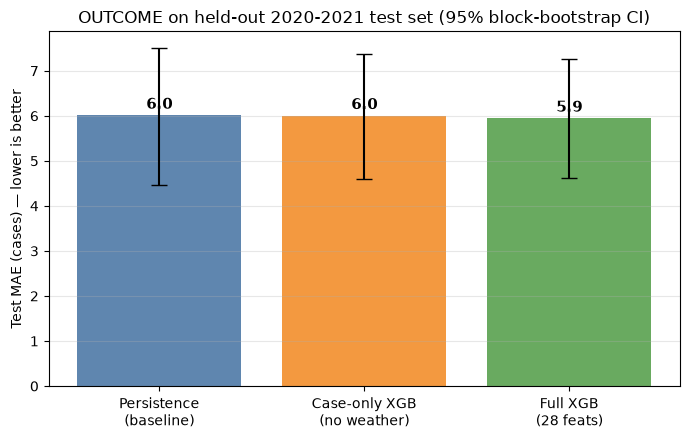

Weather ablation: case-only 6.0 -> full 5.9 (improvement +0.1, +1.0%)


In [13]:
# OUTCOME PLOT: MAE with 95% CI
abl = report['ablation']
fig, ax = plt.subplots(figsize=(7, 4.5))
names = ['persistence', 'xgb_case_only', 'xgb_full']
maes = [report['models'][m]['test']['pooled']['MAE'] for m in names]
cis = [report['models'][m]['test']['bootstrap_ci']['MAE_ci'] for m in names]
lo = [m - c[0] for m, c in zip(maes, cis)]; hi = [c[1] - m for m, c in zip(maes, cis)]
bars = ax.bar(['Persistence\n(baseline)', 'Case-only XGB\n(no weather)', 'Full XGB\n(28 feats)'], maes, yerr=[lo, hi], capsize=6, color=['#4e79a7', '#f28e2b', '#59a14f'], alpha=0.9)
for b, m in zip(bars, maes):
    ax.text(b.get_x()+b.get_width()/2, b.get_height()+0.15, f'{m:.1f}', ha='center', fontsize=11, fontweight='bold')
ax.set_ylabel('Test MAE (cases) — lower is better')
ax.set_title('OUTCOME on held-out 2020-2021 test set (95% block-bootstrap CI)')
ax.grid(axis='y', alpha=0.3)
plt.tight_layout(); plt.show()
print(f"Weather ablation: case-only {abl['case_only_MAE']:.1f} -> full {abl['full_MAE']:.1f} (improvement {abl['MAE_improvement']:+.1f}, {abl['MAE_improvement_pct']:+.1f}%)")

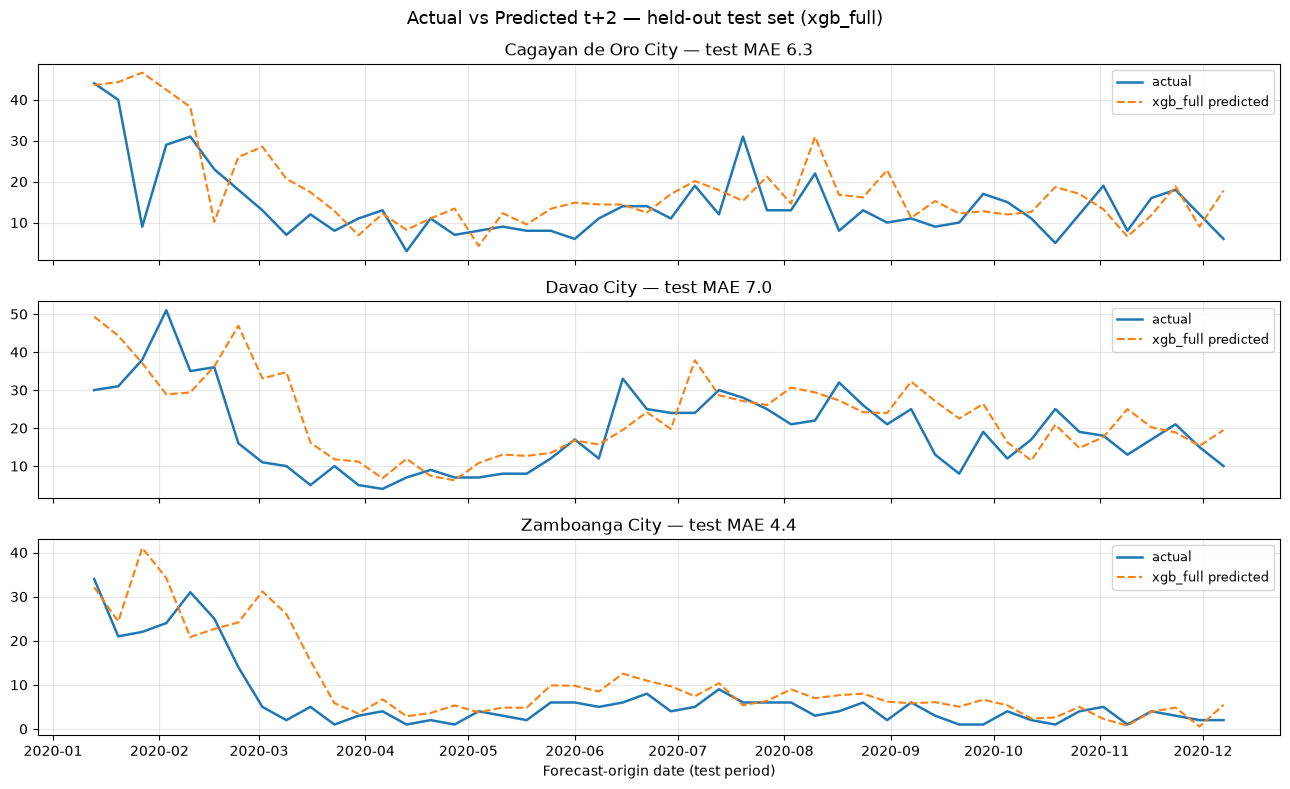

In [14]:
# OUTCOME PLOT: actual vs predicted on test set (xgb_full, per city)
import numpy as _np
test_mask = splits['test']
best = next(r for r in results if r['name'] == 'xgb_full')
pred = _np.asarray(best['predictions']['test'])
yt = y.values[test_mask]; ct = city.values[test_mask]; dt = __import__('pandas').to_datetime(__import__('pandas').Series(dates.values))[test_mask]
fig, axes = plt.subplots(3, 1, figsize=(13, 8), sharex=True)
for ax, c in zip(axes, sorted(__import__('pandas').unique(ct))):
    m = ct == c
    ax.plot(dt[m], yt[m], '-', label='actual', linewidth=1.8)
    ax.plot(dt[m], pred[m], '--', label='xgb_full predicted', linewidth=1.5)
    ax.set_title(f"{c} — test MAE {report['models']['xgb_full']['test']['per_city'][c]['MAE']:.1f}")
    ax.legend(fontsize=9); ax.grid(alpha=0.3)
axes[-1].set_xlabel('Forecast-origin date (test period)')
fig.suptitle('Actual vs Predicted t+2 — held-out test set (xgb_full)', fontsize=13)
plt.tight_layout(); plt.show()

## Takeaway for your teacher
- **Leakage-free:** past-only features, temporal split + 2-week embargo, tuning on train only.
- **Outcome = test-set table + CI plot above:** persistence vs case-only XGB vs full 28-feature XGB on 2020-2021 weeks the model never saw.
- **Weather ablation** (case-only → full) = effect of meteorological features. Full report saved to `outputs/results.json`.